# Punto 2 — Clasificación de eventos MAGIC

## 1. Optimización de modelos mediante gradiente y metaheurísticas

### Objetivo

Comparar el comportamiento de dos modelos de clasificación binaria —**regresión logística** y **red neuronal**— al optimizar sus parámetros con cuatro métodos: **descenso por gradiente, algoritmo genético (GA), optimización por enjambre de partículas (PSO) y recocido simulado (SA)**.

Este notebook presenta las decisiones metodológicas, visualiza los resultados que **ya generamos** y explica **qué se observó y por qué pudo ocurrir**. No vuelve a entrenar los modelos, de modo que el conjunto de prueba se mantiene como evidencia de la evaluación final y no se utiliza para seguir ajustando configuraciones.

### Actividades

- Describir la base de datos MAGIC y el problema de clasificación.
- Explicar la preparación de los datos y la arquitectura de los modelos.
- Describir el funcionamiento de los cuatro optimizadores.
- Comparar métricas, pérdidas y matrices de confusión en validación.
- Analizar la estabilidad con tres semillas aleatorias.
- Interpretar la evaluación final sobre registros de prueba reservados.
- Redactar conclusiones y limitaciones del experimento.

> **Convención del proyecto:** `Class = 1` corresponde a eventos **gamma (`g`)** y `Class = 0` a eventos **hadrónicos (`h`)**. Las cifras experimentales se leen desde los CSV de `resultados/punto_2/`.

## 2. Configuración del entorno

Usamos el mismo entorno virtual `.venv` de los notebooks anteriores. Los modelos y algoritmos permanecen en archivos `.py` dentro de `src/punto_2/`; aquí **recuperamos las métricas y generamos visualizaciones**, sin duplicar el código de entrenamiento.

In [17]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import ConfusionMatrixDisplay

# Ubicar automáticamente la raíz desde notebooks/ o desde la raíz del proyecto.
ubicacion = Path.cwd().resolve()
RAIZ = next(
    (p for p in [ubicacion, *ubicacion.parents] if (p / "src" / "punto_2").is_dir()),
    None
)
if RAIZ is None:
    raise RuntimeError(
        "No se encontró src/punto_2. Abre Proyecto_Machine_Learning en VS Code "
        "y selecciona el kernel de .venv."
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

RESULTADOS = RAIZ / "resultados" / "punto_2"
DATOS = RAIZ / "data" / "raw" / "magic.csv"

pd.set_option("display.max_columns", 25)
print("Proyecto:", RAIZ)
print("Intérprete:", sys.executable)
print("Resultados:", RESULTADOS)

Proyecto: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning
Intérprete: c:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\.venv\Scripts\python.exe
Resultados: C:\Users\Santiago\Documents\Santiago\Proyectos\Proyecto_Machine_Learning\resultados\punto_2


## 3. Descripción de la base de datos MAGIC

MAGIC contiene observaciones simuladas de un telescopio de rayos gamma. El objetivo supervisado consiste en distinguir eventos **gamma** (`g`) de eventos **hadrónicos** (`h`) usando diez características numéricas.

En el proyecto, `magic.csv` contiene una **primera fila de metadatos**. La lectura correcta utiliza `skiprows=1` para conservar los nombres de las diez características y la etiqueta `Class`.

In [18]:
if not DATOS.is_file():
    raise FileNotFoundError(f"No existe el archivo de datos: {DATOS}")

df_magic = pd.read_csv(DATOS, skiprows=1)
df_magic.columns = df_magic.columns.str.strip()

if "Class" not in df_magic.columns:
    raise ValueError("El archivo MAGIC no contiene la columna Class.")

resumen_clases = df_magic["Class"].astype(str).str.strip().value_counts()
resumen = pd.DataFrame({
    "Clase": ["Gamma (g → 1)", "Hadrón (h → 0)"],
    "Registros": [int(resumen_clases.get("g", 0)), int(resumen_clases.get("h", 0))],
})
resumen["Porcentaje (%)"] = 100 * resumen["Registros"] / len(df_magic)

print("Dimensiones:", df_magic.shape)
print("Características:", df_magic.shape[1] - 1)
print("Nulos totales:", int(df_magic.isna().sum().sum()))
display(resumen.round(3))
display(df_magic.head(3))

Dimensiones: (19020, 11)
Características: 10
Nulos totales: 0


,Clase,Registros,Porcentaje (%)
0,Gamma (g → 1),12332,64.837
1,Hadrón (h → 0),6688,35.163


,Flength,Fwidth,Fsize,Fconc,Fconc1,Fasym,Fm3long,Fm3trans,Falpha,Fdist,Class
0,28.7967,16.0021,2.6449,0.3918,0.1982,27.7004,22.0110,-8.2027,40.0920,81.8828,g
1,31.6036,11.7235,2.5185,0.5303,0.3773,26.2722,23.8238,-9.9574,6.3609,205.2610,g
2,162.0520,136.0310,4.0612,0.0374,0.0187,116.7410,-64.8580,-45.2160,76.9600,256.7880,g


### Interpretación del conjunto de datos

Se analizaron **19.020 observaciones**, con **10 variables de entrada** y **una clase objetivo**. De ellas, **12.332** corresponden a gamma (64,84 %) y **6.688** a hadrones (35,16 %). No se encontraron valores nulos después de omitir la fila de metadatos.

El desbalance de MAGIC es **moderado**, muy distinto del desbalance extremo del conjunto de fraude del punto 1. Aun así, no conviene evaluar los clasificadores solo mediante exactitud: la **precisión**, **sensibilidad** y el **F1-score** explican mejor qué tipo de errores están cometiendo.

## 4. Preparación y separación de los datos

Se realizó una **partición estratificada inicial del 80 % para entrenamiento y 20 % para prueba**. Para comparar los optimizadores se reservó internamente el 20 % del entrenamiento como conjunto de validación.

| Uso | Registros | Propósito |
|---|---:|---|
| Entrenamiento interno | 12.172 | Ajustar los parámetros durante la comparación |
| Validación interna | 3.044 | Comparar los ocho experimentos y seleccionar métodos |
| Prueba final reservada | 3.804 | Evaluar las configuraciones seleccionadas una sola vez |

Durante la validación se ajustó `StandardScaler` exclusivamente con el entrenamiento interno. Para la evaluación final, el escalador se reajustó usando los **15.216 registros de entrenamiento** y se aplicó a los 3.804 de prueba. Esto evita que las estadísticas del conjunto evaluado influyan en el aprendizaje.

> **Precaución:** los resultados de prueba no se usan para elegir optimizadores ni para modificar hiperparámetros.

,Conjunto,Registros,Participación sobre MAGIC (%)
0,Entrenamiento interno,12172,64.0
1,Validación interna,3044,16.0
2,Prueba reservada,3804,20.0


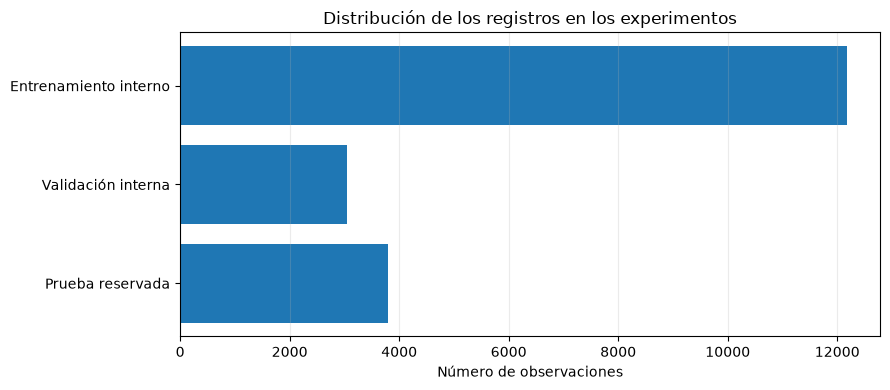

In [19]:
particiones = pd.DataFrame({
    "Conjunto": ["Entrenamiento interno", "Validación interna", "Prueba reservada"],
    "Registros": [12172, 3044, 3804],
    "Participación sobre MAGIC (%)": np.array([12172, 3044, 3804]) / 19020 * 100,
})
display(particiones.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(particiones["Conjunto"], particiones["Registros"])
ax.set_title("Distribución de los registros en los experimentos")
ax.set_xlabel("Número de observaciones")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Modelos evaluados

### Regresión logística

Calcula una **combinación lineal** de las diez características y la transforma en probabilidad mediante una función sigmoide. Tiene **11 parámetros**: diez pesos y un sesgo.

### Regresión neuronal

Se utilizó una red **10 → 4 → 1**, con cuatro neuronas en la capa oculta (`tanh`) y una salida sigmoide. Tiene **49 parámetros** (40 pesos de entrada, cuatro sesgos ocultos, cuatro pesos de salida y un sesgo final).

Ambos modelos optimizan la **misma clase de función objetivo**: entropía cruzada binaria con regularización. Lo que cambia entre experimentos es **cómo se buscan los parámetros**.

**Posible causa de diferencias:** la red puede representar interacciones no lineales que la regresión logística no captura directamente; sin embargo, disponer de más parámetros también hace más compleja su optimización.

In [20]:
modelos = pd.DataFrame({
    "Modelo": ["Regresión logística", "Regresión neuronal (MLP)"],
    "Arquitectura": ["10 características → sigmoide", "10 → 4 (tanh) → 1 (sigmoide)"],
    "Parámetros": [11, 49],
    "Tipo de frontera": ["Lineal", "No lineal"],
})
display(modelos)

,Modelo,Arquitectura,Parámetros,Tipo de frontera
0,Regresión logística,10 características → sigmoide,11,Lineal
1,Regresión neuronal (MLP),10 → 4 (tanh) → 1 (sigmoide),49,No lineal


## 6. ¿Cómo se optimizaron los modelos?

Se probaron cuatro algoritmos de optimización:

- **Descenso por gradiente:** actualiza los parámetros siguiendo la dirección que reduce localmente la pérdida; utiliza derivadas.
- **Algoritmo genético (GA):** mantiene una población de candidatos y utiliza selección, cruce, mutación y elitismo.
- **PSO:** las partículas modifican sus posiciones según sus mejores soluciones personales y la mejor solución del enjambre.
- **Simulated Annealing (SA):** explora una solución a la vez y puede aceptar empeoramientos para escapar de ciertas regiones de búsqueda.

### Configuración experimental inicial

| Método | Presupuesto configurado | Consideración |
|---|---|---|
| Gradiente | 150 iteraciones | Cada iteración calcula pérdida **y gradiente** |
| GA | 20 individuos × 40 generaciones = 800 evaluaciones | Búsqueda poblacional |
| PSO | 20 partículas × 40 iteraciones = 800 evaluaciones | Búsqueda poblacional |
| SA | 800 evaluaciones | Búsqueda local probabilística |

**Advertencia metodológica:** 150 evaluaciones de pérdida y gradiente **no cuestan lo mismo** que 800 evaluaciones de pérdida. Estos presupuestos permiten una comparación experimental inicial, pero **no** una prueba de superioridad bajo recursos computacionales estrictamente equivalentes.

## 7. Cargar las ocho combinaciones de validación

Los programas originales guardaron las métricas en carpetas independientes. El archivo `comparacion_completa.csv` reúne **dos modelos × cuatro optimizadores = ocho resultados**.

Los resultados que aparecen a continuación corresponden a los **3.044 registros de validación interna**, no a la prueba final.

In [21]:
ruta_comparacion = RESULTADOS / "comparacion" / "comparacion_completa.csv"
if not ruta_comparacion.is_file():
    raise FileNotFoundError(
        f"No se encontró {ruta_comparacion}. Ejecuta previamente "
        "python -m src.punto_2.comparar_optimizadores"
    )

comparacion = pd.read_csv(ruta_comparacion)
comparacion = comparacion.drop_duplicates(
    subset=["modelo", "optimizador"], keep="last"
)

columnas_validacion = [
    "modelo", "optimizador", "perdida", "exactitud", "precision",
    "sensibilidad", "f1_score"
]
faltantes = set(columnas_validacion) - set(comparacion.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en comparacion_completa.csv: {sorted(faltantes)}")

print("Combinaciones cargadas:", len(comparacion))
display(comparacion[columnas_validacion].round(4))

Combinaciones cargadas: 8


,modelo,optimizador,perdida,exactitud,precision,sensibilidad,f1_score
0,regresion_logistica,Gradiente,0.4632,0.7802,0.7886,0.9032,0.8420
1,regresion_neuronal,Gradiente,0.4919,0.7733,0.7818,0.9022,0.8377
2,regresion_logistica,Genético,0.4565,0.7835,0.7971,0.8936,0.8426
3,regresion_neuronal,Genético,0.4540,0.7842,0.8059,0.8789,0.8408
4,regresion_logistica,PSO,0.4547,0.7838,0.7956,0.8972,0.8433
5,regresion_neuronal,PSO,0.4044,0.8216,0.8383,0.8982,0.8672
6,regresion_logistica,SA,0.5569,0.7503,0.7896,0.8384,0.8133
7,regresion_neuronal,SA,0.5971,0.7037,0.7587,0.7964,0.7771


## 8. Comparación de F1-score en validación

El **F1-score de la clase gamma** combina precisión y sensibilidad: penaliza tanto las falsas alarmas (hadrones clasificados como gamma) como los eventos gamma no detectados.

En la ejecución inicial, **PSO** obtuvo el mayor F1 para ambos modelos: aproximadamente **0,8433** en regresión logística y **0,8672** en la red neuronal. La ventaja fue especialmente visible en el modelo neuronal.

> Este ranking corresponde a una ejecución y no demuestra que el mismo método gane para todas las semillas.

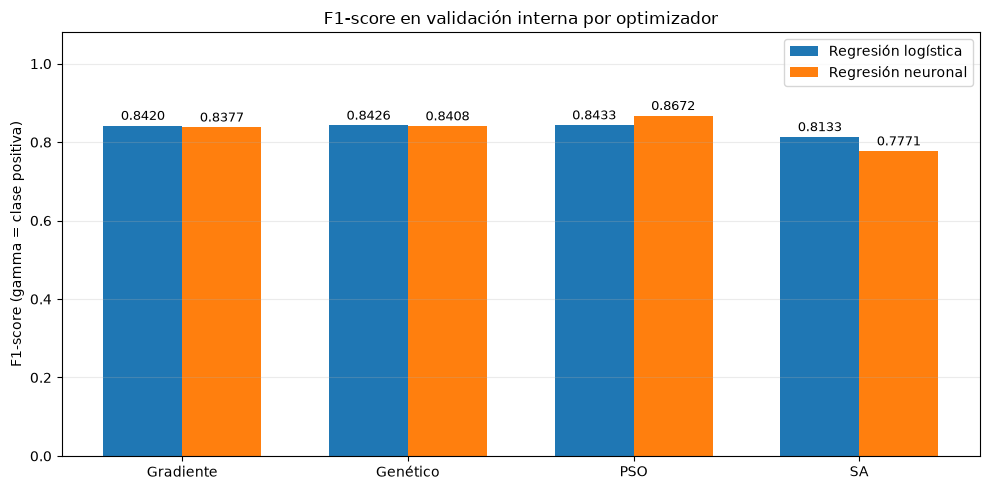

In [22]:
orden_metodos = ["Gradiente", "Genético", "PSO", "SA"]
orden_modelos = ["regresion_logistica", "regresion_neuronal"]
etiquetas_modelos = {
    "regresion_logistica": "Regresión logística",
    "regresion_neuronal": "Regresión neuronal",
}

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(orden_metodos))
ancho = 0.35
for i, modelo in enumerate(orden_modelos):
    subset = comparacion[comparacion["modelo"] == modelo].set_index("optimizador")
    valores = subset.reindex(orden_metodos)["f1_score"]
    barras = ax.bar(x + (i - 0.5) * ancho, valores, width=ancho,
                    label=etiquetas_modelos[modelo])
    ax.bar_label(barras, fmt="%.4f", padding=2, fontsize=9)
ax.set_xticks(x, orden_metodos)
ax.set_ylim(0, 1.08)
ax.set_title("F1-score en validación interna por optimizador")
ax.set_ylabel("F1-score (gamma = clase positiva)")
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### ¿Por qué pudo destacar PSO?

PSO combina **exploración** (distintas partículas recorren el espacio) y **aprovechamiento** (las soluciones se acercan a posiciones prometedoras). Para una red con 49 parámetros, esta búsqueda colectiva pudo encontrar combinaciones que los otros métodos no alcanzaron dentro de los presupuestos utilizados.

Es una **interpretación plausible**, no una causa demostrada: la diferencia también depende de las semillas, la tasa de aprendizaje, la arquitectura y el número de evaluaciones de cada método.

## 9. Pérdida de entrenamiento, precisión y sensibilidad

La **pérdida** resume qué tan bien se ajustan las probabilidades del modelo a las etiquetas de entrenamiento. Una pérdida menor es favorable en los mismos datos y con la misma función objetivo, pero **no garantiza** por sí sola un mayor F1 en validación.

La **precisión** indica qué proporción de predicciones gamma son correctas. La **sensibilidad** indica qué proporción de los gamma reales fueron detectados. Su equilibrio ayuda a explicar las diferencias de F1.

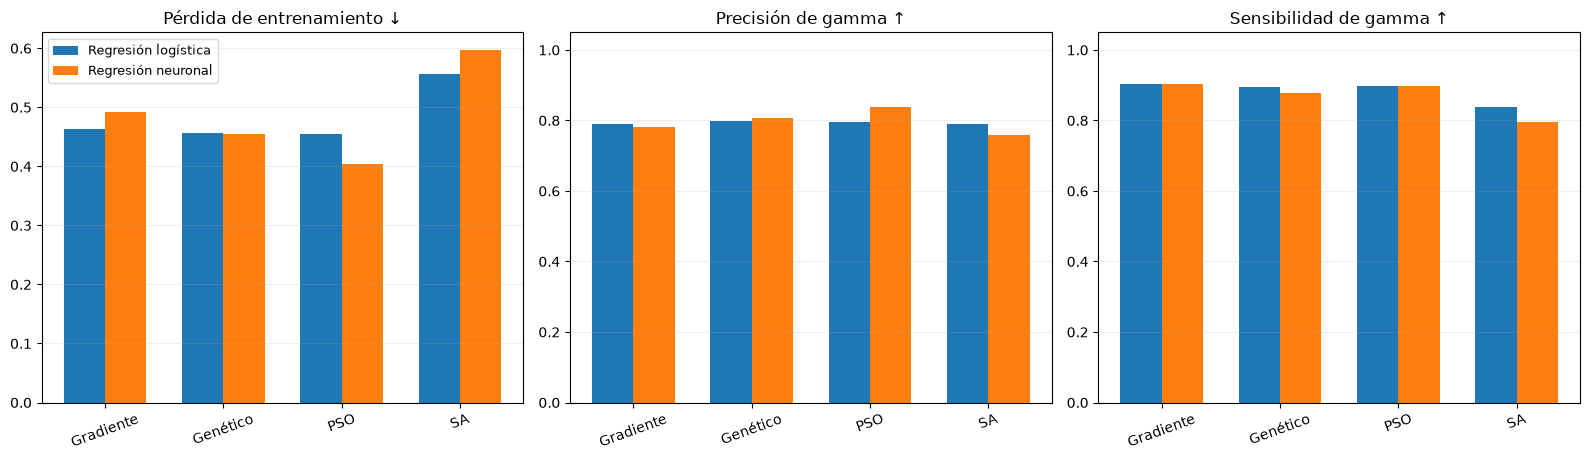

In [23]:
metricas = ["perdida", "precision", "sensibilidad"]
titulos = ["Pérdida de entrenamiento ↓", "Precisión de gamma ↑", "Sensibilidad de gamma ↑"]
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.7))
x = np.arange(len(orden_metodos))

for ax, metrica, titulo in zip(ejes, metricas, titulos):
    for i, modelo in enumerate(orden_modelos):
        sub = comparacion[comparacion["modelo"] == modelo].set_index("optimizador")
        valores = sub.reindex(orden_metodos)[metrica]
        ax.bar(x + (i - 0.5) * 0.35, valores, width=0.35,
               label=etiquetas_modelos[modelo])
    ax.set_xticks(x, orden_metodos, rotation=20)
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.2)
    if metrica != "perdida":
        ax.set_ylim(0, 1.05)
ejes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

### Lectura de las métricas

- **Regresión logística:** gradiente, GA y PSO mostraron resultados de F1 muy próximos. Las diferencias pequeñas desaconsejan declarar un ganador universal.
- **Regresión neuronal:** PSO combinó menor pérdida con mejor precisión y F1 en la ejecución inicial; el descenso por gradiente alcanzó sensibilidad alta, pero tuvo más falsos positivos.
- **SA:** obtuvo mayor pérdida y menor F1 bajo los hiperparámetros ensayados. Esto puede deberse a la **escala de perturbaciones**, al **calendario de temperatura** y al presupuesto, no a una incapacidad general de SA.

En problemas reales, un falso positivo y un falso negativo pueden tener costos distintos; por ello, F1 es útil pero no suficiente por sí solo para decidir.

## 10. Curvas de convergencia

Las curvas registran la pérdida durante la optimización. Para **GA, PSO y SA** se observa la *mejor pérdida acumulada*, que no puede aumentar; para **gradiente** se observa la pérdida de las iteraciones sucesivas.

**No deben compararse los valores del eje horizontal como si representaran el mismo costo:** las gráficas usan iteraciones, generaciones o evaluaciones según el algoritmo.

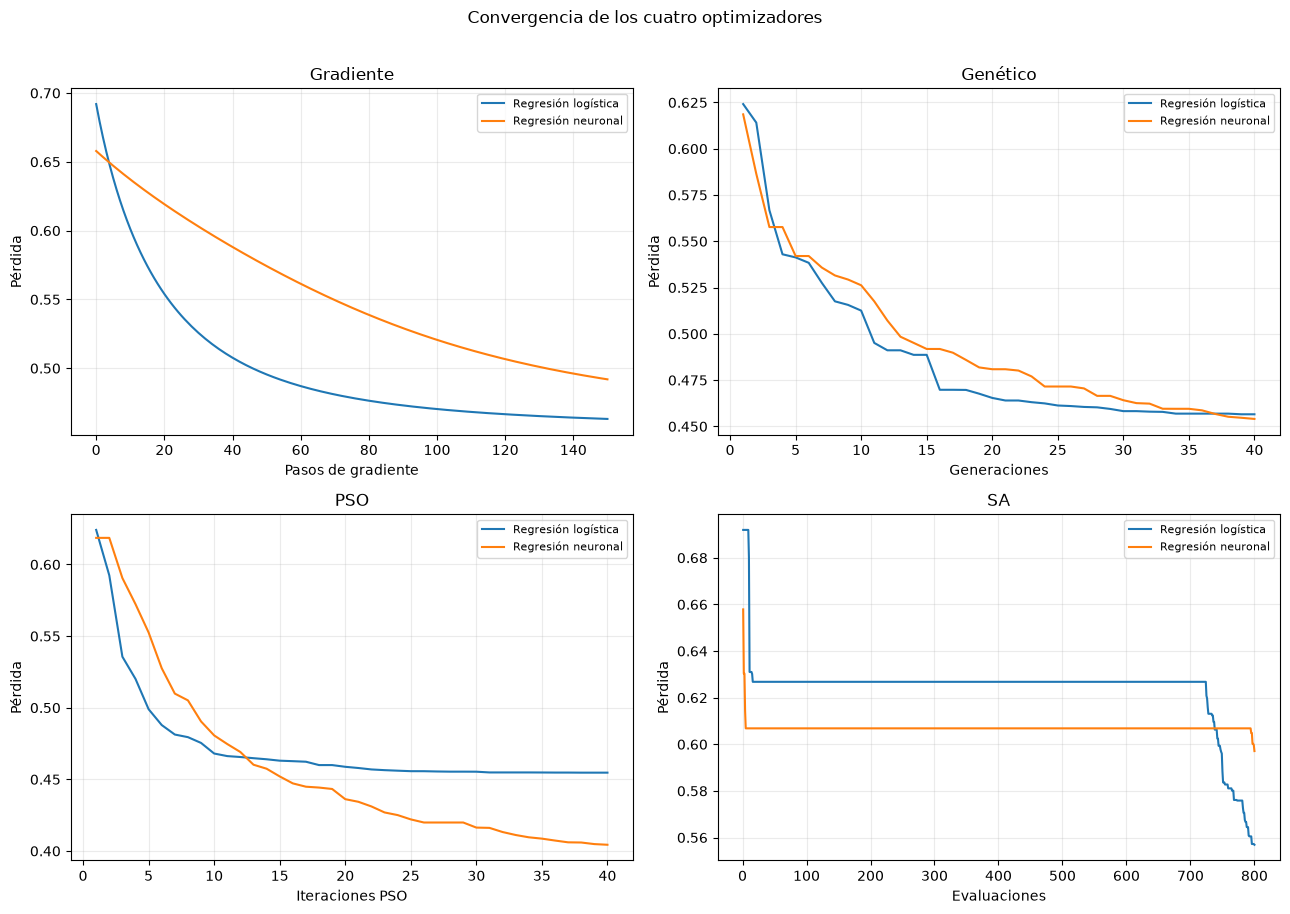

In [24]:
archivos_historial = {
    "Gradiente": RESULTADOS / "gradiente" / "historial_gradiente.csv",
    "Genético": RESULTADOS / "genetico" / "historial_genetico.csv",
    "PSO": RESULTADOS / "pso" / "historial_pso.csv",
    "SA": RESULTADOS / "simulated_annealing" / "historial_sa.csv",
}

fig, ejes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (metodo, ruta) in zip(ejes.flat, archivos_historial.items()):
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró el historial de {metodo}: {ruta}")
    hist = pd.read_csv(ruta)
    for modelo in orden_modelos:
        if modelo not in hist.columns:
            raise ValueError(f"El historial de {metodo} no contiene {modelo}")
        serie = hist[modelo].dropna().to_numpy()
        eje_x = np.arange(len(serie)) if metodo == "Gradiente" else np.arange(1, len(serie) + 1)
        ax.plot(eje_x, serie, label=etiquetas_modelos[modelo])
    ax.set_title(metodo)
    ax.set_xlabel("Pasos de gradiente" if metodo == "Gradiente" else
                  "Evaluaciones" if metodo == "SA" else
                  "Generaciones" if metodo == "Genético" else "Iteraciones PSO")
    ax.set_ylabel("Pérdida")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
plt.suptitle("Convergencia de los cuatro optimizadores", y=1.01)
plt.tight_layout()
plt.show()

### ¿Qué nos dicen las curvas?

Las pérdidas de los cuatro métodos disminuyeron respecto a sus valores iniciales, pero a ritmos distintos.

- La **regresión logística** tiene una función de pérdida suave y convexa respecto a sus parámetros. Los métodos pueden alcanzar pérdidas similares si tienen recursos suficientes.
- La **red neuronal** tiene una superficie de optimización no convexa, con interacciones entre parámetros; por eso su resultado puede depender más de la inicialización y de la estrategia de búsqueda.
- En la ejecución observada, **SA mostró largos tramos sin mejorar el mejor valor acumulado**. Esto indica que sus propuestas no encontraron una solución global mejor durante esos intervalos; no significa necesariamente que no se aceptaran movimientos internos.

No podemos asegurar convergencia al óptimo global a partir de estas gráficas.

## 11. Matrices de confusión de validación: comparación de errores

La matriz de confusión distingue cuatro casos:

| | Predicho hadrón (0) | Predicho gamma (1) |
|---|---|---|
| **Real hadrón (0)** | Verdadero negativo (VN) | Falso positivo (FP) |
| **Real gamma (1)** | Falso negativo (FN) | Verdadero positivo (VP) |

Las siguientes matrices corresponden a **regresión neuronal**, evaluada con cada optimizador sobre los 3.044 registros de validación interna.

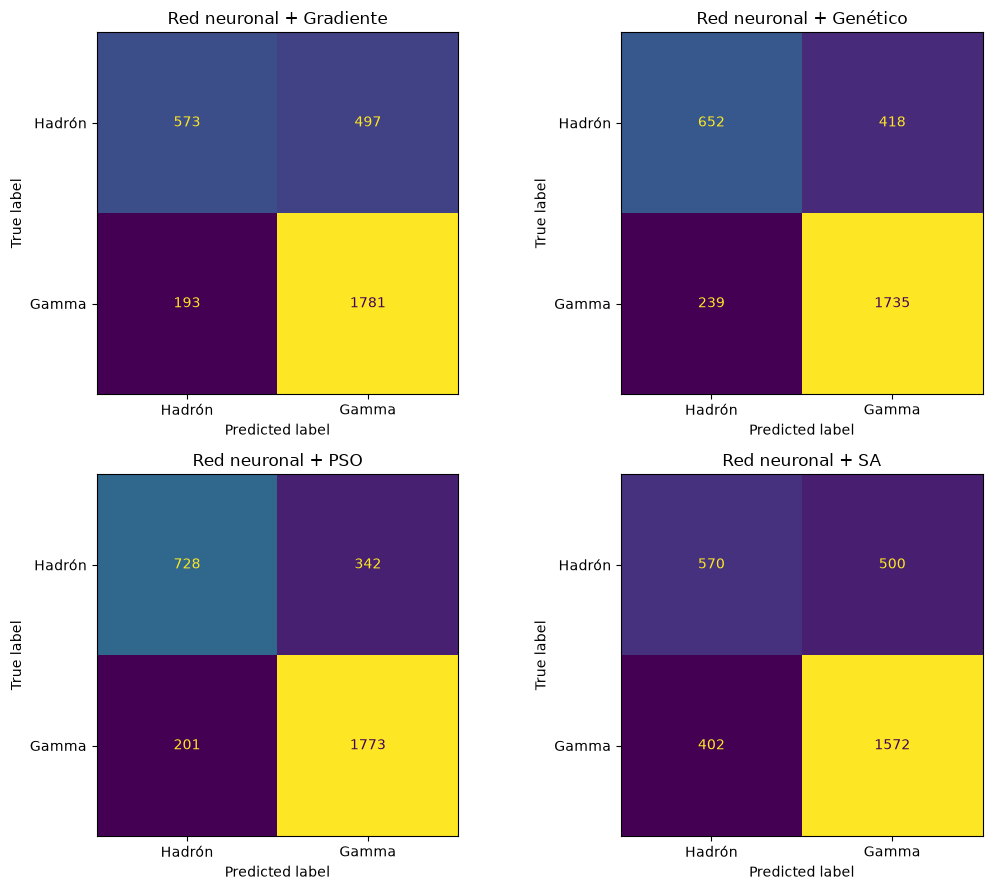

,Optimizador,Falsos positivos,Falsos negativos,Verdaderos positivos
0,Gradiente,497,193,1781
1,Genético,418,239,1735
2,PSO,342,201,1773
3,SA,500,402,1572


In [25]:
carpetas_matrices = {
    "Gradiente": "gradiente",
    "Genético": "genetico",
    "PSO": "pso",
    "SA": "simulated_annealing",
}

fig, ejes = plt.subplots(2, 2, figsize=(11, 9))
filas_error = []
for ax, (nombre, carpeta) in zip(ejes.flat, carpetas_matrices.items()):
    ruta = RESULTADOS / carpeta / "matriz_regresion_neuronal.csv"
    if not ruta.is_file():
        raise FileNotFoundError(f"No existe la matriz de validación: {ruta}")
    matriz = pd.read_csv(ruta, index_col=0).to_numpy(dtype=int)
    if matriz.shape != (2, 2):
        raise ValueError(f"Matriz no válida ({matriz.shape}): {ruta}")
    ConfusionMatrixDisplay(matriz, display_labels=["Hadrón", "Gamma"]).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(f"Red neuronal + {nombre}")
    vn, fp, fn, vp = matriz.ravel()
    filas_error.append({"Optimizador": nombre, "Falsos positivos": fp,
                        "Falsos negativos": fn, "Verdaderos positivos": vp})
plt.tight_layout()
plt.show()

errores_validacion = pd.DataFrame(filas_error)
display(errores_validacion)

### ¿Por qué importa la matriz de confusión?

Una **sensibilidad alta** puede obtenerse a costa de clasificar demasiados hadrones como gamma. Los falsos positivos reducen la precisión. Por eso, al comparar optimizadores, no basta con decir cuál detectó más gamma: también debemos observar **cuántas falsas alarmas produjo**.

En la validación inicial de la red neuronal, PSO redujo los falsos positivos frente al descenso por gradiente, manteniendo una sensibilidad próxima. Esto explica buena parte de su mejora en precisión y F1.

## 12. Estabilidad: tres semillas aleatorias

Repetimos cada combinación con las semillas **42, 123 y 2026**: **24 entrenamientos** en total. Esta prueba permite observar cuánto cambia el F1-score por la inicialización y la aleatoriedad de cada optimizador, **manteniendo la misma división de validación**.

Utilizamos **promedio** y **desviación estándar**: un F1 promedio mayor es favorable, mientras que una desviación menor sugiere menor variabilidad en estas tres ejecuciones.

> Tres semillas son útiles como verificación exploratoria, pero no constituyen una prueba estadística concluyente ni evalúan variaciones de partición de datos.

In [26]:
ruta_semillas = RESULTADOS / "comparacion_semillas" / "resultados_semillas.csv"
ruta_resumen = RESULTADOS / "comparacion_semillas" / "resumen_semillas.csv"
for ruta in (ruta_semillas, ruta_resumen):
    if not ruta.is_file():
        raise FileNotFoundError(
            f"No existe {ruta}. Ejecuta primero "
            "python -m src.punto_2.validacion_semillas"
        )

repeticiones = pd.read_csv(ruta_semillas)
resumen_semillas = pd.read_csv(ruta_resumen)
print("Entrenamientos registrados:", len(repeticiones))
print("Semillas:", sorted(repeticiones["semilla"].unique().tolist()))
display(resumen_semillas[[
    "modelo", "optimizador", "f1_promedio", "f1_std", "precision_promedio",
    "sensibilidad_promedio", "perdida_promedio", "repeticiones"
]].round(4))

Entrenamientos registrados: 24
Semillas: [42, 123, 2026]


,modelo,optimizador,f1_promedio,f1_std,precision_promedio,sensibilidad_promedio,perdida_promedio,repeticiones
0,regresion_logistica,Genetico,0.8442,0.0024,0.7974,0.8970,0.4572,3
1,regresion_logistica,PSO,0.8439,0.0005,0.7975,0.8960,0.4548,3
2,regresion_logistica,Gradiente,0.8420,0.0002,0.7886,0.9032,0.4632,3
3,regresion_logistica,SA,0.8250,0.0170,0.7871,0.8671,0.5376,3
4,regresion_neuronal,PSO,0.8486,0.0164,0.8248,0.8744,0.4296,3
5,regresion_neuronal,Genetico,0.8396,0.0063,0.8031,0.8796,0.4605,3
6,regresion_neuronal,Gradiente,0.8250,0.0157,0.7528,0.9146,0.5234,3
7,regresion_neuronal,SA,0.7955,0.0176,0.7480,0.8528,0.5785,3


## 13. F1 promedio y variabilidad

En regresión logística, **GA y PSO quedaron prácticamente empatados**: GA obtuvo un F1 promedio de aproximadamente **0,8442** y PSO **0,8439**. La diferencia es de solo **0,0003**, demasiado pequeña para inferir superioridad con tres repeticiones.

En regresión neuronal, **PSO** obtuvo el mayor promedio (**0,8486**), pero su variación fue mayor que la de GA. La selección debe considerar **rendimiento medio y estabilidad**, además de la pérdida.

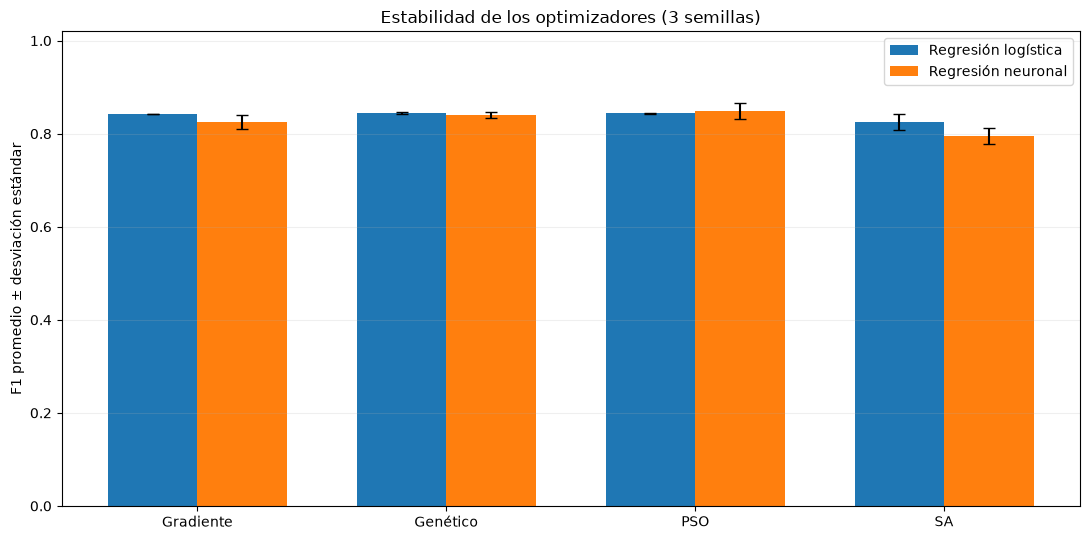

In [27]:
nombres_semillas = ["Gradiente", "Genetico", "PSO", "SA"]
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(nombres_semillas))
for i, modelo in enumerate(orden_modelos):
    sub = resumen_semillas[resumen_semillas["modelo"] == modelo].set_index("optimizador")
    sub = sub.reindex(nombres_semillas)
    y = sub["f1_promedio"].to_numpy(dtype=float)
    sd = sub["f1_std"].to_numpy(dtype=float)
    ax.bar(x + (i - 0.5) * 0.36, y, 0.36,
           yerr=sd, capsize=4, label=etiquetas_modelos[modelo])
ax.set_xticks(x, ["Gradiente", "Genético", "PSO", "SA"])
ax.set_ylabel("F1 promedio ± desviación estándar")
ax.set_ylim(0, 1.02)
ax.set_title("Estabilidad de los optimizadores (3 semillas)")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### Interpretación de la variabilidad

- **Logística + GA:** mejor F1 promedio, por una diferencia mínima respecto a PSO.
- **Logística + PSO:** menor variación de F1 que GA entre las tres semillas.
- **Neuronal + PSO:** mejor F1 promedio, aunque no fue el método neuronal más estable.
- **Neuronal + GA:** promedio algo inferior, pero menor desviación estándar que PSO.
- **SA:** resultado promedio inferior y relativamente sensible a la semilla bajo estos hiperparámetros.

Estas observaciones muestran por qué una única ejecución puede ser engañosa: los rankings cambian ligeramente cuando repetimos el experimento.

## 14. Selección de las dos configuraciones finalistas

Se seleccionaron **antes de consultar el conjunto de prueba**:

1. **Regresión logística + algoritmo genético**, por el mayor F1 promedio en su familia.
2. **Regresión neuronal + PSO**, por el mayor F1 promedio entre las configuraciones neuronales.

Los modelos finalistas se volvieron a entrenar usando los **15.216 registros de entrenamiento** y se evaluaron posteriormente en los **3.804 registros reservados**. Se mantuvieron las configuraciones de optimización y la semilla 42 para el ajuste final.

La elección no implica que las configuraciones sean óptimas globalmente; es la mejor elección dentro de las comparaciones realizadas.

In [28]:
seleccion = pd.DataFrame({
    "Modelo": ["Regresión logística", "Regresión neuronal"],
    "Optimizador seleccionado": ["Genético", "PSO"],
    "Criterio": ["Mayor F1 promedio de la familia", "Mayor F1 promedio de la familia"],
})
seleccion["F1 promedio de validación"] = [
    float(resumen_semillas.query("modelo == 'regresion_logistica' and optimizador == 'Genetico'")["f1_promedio"].iloc[0]),
    float(resumen_semillas.query("modelo == 'regresion_neuronal' and optimizador == 'PSO'")["f1_promedio"].iloc[0]),
]
display(seleccion.round(4))

,Modelo,Optimizador seleccionado,Criterio,F1 promedio de validación
0,Regresión logística,Genético,Mayor F1 promedio de la familia,0.8442
1,Regresión neuronal,PSO,Mayor F1 promedio de la familia,0.8486


## 15. Evaluación final en registros no utilizados para la selección

Las cuatro métricas principales son:

- **Exactitud:** proporción de predicciones correctas en ambas clases.
- **Precisión gamma:** proporción de alertas gamma que eran gamma.
- **Sensibilidad gamma:** proporción de gamma reales correctamente detectados.
- **F1-score gamma:** media armónica entre precisión y sensibilidad.

También calcularemos **especificidad** a partir de los verdaderos negativos y los falsos positivos, para conocer qué proporción de hadrones se reconoce correctamente.

In [29]:
ruta_final = RESULTADOS / "evaluacion_final" / "metricas_finales.csv"
if not ruta_final.is_file():
    raise FileNotFoundError(
        f"No se encontró {ruta_final}. Ejecuta previamente "
        "python -m src.punto_2.evaluacion_final"
    )

prueba = pd.read_csv(ruta_final)
prueba = prueba.drop_duplicates(subset=["modelo", "optimizador"], keep="last")
columnas_finales = [
    "modelo", "optimizador", "exactitud", "precision", "sensibilidad", "f1_score",
    "verdaderos_negativos", "falsos_positivos", "falsos_negativos", "verdaderos_positivos"
]
faltan = set(columnas_finales) - set(prueba.columns)
if faltan:
    raise ValueError(f"Faltan columnas en metricas_finales.csv: {sorted(faltan)}")

prueba["especificidad"] = prueba["verdaderos_negativos"] / (
    prueba["verdaderos_negativos"] + prueba["falsos_positivos"]
)
prueba["identificador"] = prueba["modelo"] + " + " + prueba["optimizador"]

print("Modelos finalistas:", len(prueba))
display(prueba[[
    "identificador", "exactitud", "precision", "sensibilidad", "especificidad", "f1_score"
]].round(4))

Modelos finalistas: 2


,identificador,exactitud,precision,sensibilidad,especificidad,f1_score
0,regresion_logistica + genetico,0.7768,0.7893,0.8946,0.5598,0.8386
1,regresion_neuronal + pso,0.8028,0.8187,0.8938,0.6353,0.8546


### ¿Cuál fue el mejor modelo en prueba?

En la evaluación final, **regresión neuronal + PSO** obtuvo **F1 = 0,8546** y **exactitud = 0,8028**, por encima de **regresión logística + GA** (**F1 = 0,8386**, **exactitud = 0,7768**).

La **sensibilidad gamma** fue prácticamente igual en ambas configuraciones, mientras que la red neuronal obtuvo **mejor precisión** y **mejor especificidad**. Esto sugiere que su principal ventaja fue **reducir las falsas alarmas** sin sacrificar de manera importante la detección de gamma.

Estos resultados pertenecen a los **dos finalistas seleccionados**; no implican que los otros seis modelos hayan sido evaluados nuevamente en prueba.

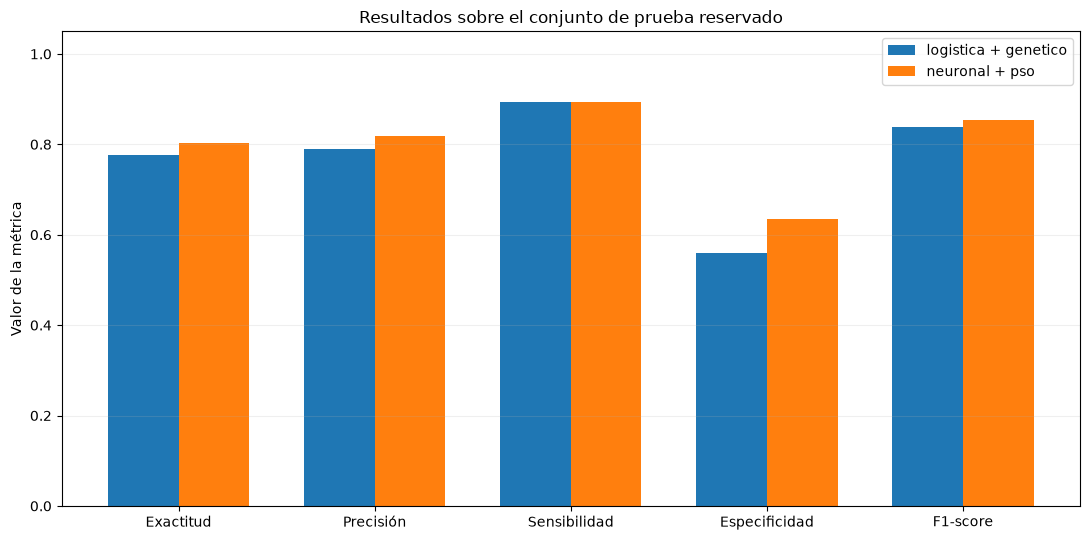

In [30]:
metricas_prueba = ["exactitud", "precision", "sensibilidad", "especificidad", "f1_score"]
nombres_metricas = ["Exactitud", "Precisión", "Sensibilidad", "Especificidad", "F1-score"]

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(metricas_prueba))
for i, (_, fila) in enumerate(prueba.iterrows()):
    valores = fila[metricas_prueba].astype(float).to_numpy()
    ax.bar(x + (i - 0.5) * 0.36, valores, width=0.36,
           label=fila["identificador"].replace("regresion_", ""))
ax.set_xticks(x, nombres_metricas)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Valor de la métrica")
ax.set_title("Resultados sobre el conjunto de prueba reservado")
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 16. Matrices de confusión de la evaluación final

La matriz permite interpretar **qué errores concretos** están detrás de los promedios:

- **FP:** hadrón etiquetado erróneamente como gamma.
- **FN:** gamma real etiquetado erróneamente como hadrón.

En los resultados observados, la red neuronal con PSO cometió **101 falsos positivos menos** que la regresión logística con GA, pero tuvo **dos falsos negativos más**. Esto ayuda a explicar por qué su precisión y F1 fueron superiores, mientras que la sensibilidad quedó prácticamente igual.

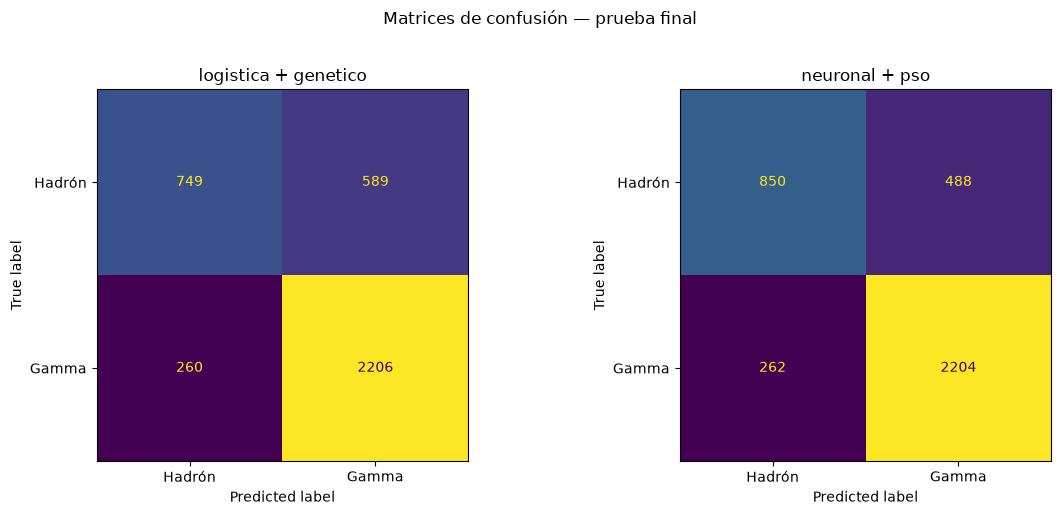

,identificador,falsos_positivos,falsos_negativos,verdaderos_positivos,verdaderos_negativos
0,regresion_logistica + genetico,589,260,2206,749
1,regresion_neuronal + pso,488,262,2204,850


In [31]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (_, fila) in zip(ejes, prueba.iterrows()):
    matriz = np.array([
        [int(fila["verdaderos_negativos"]), int(fila["falsos_positivos"])],
        [int(fila["falsos_negativos"]), int(fila["verdaderos_positivos"])],
    ])
    ConfusionMatrixDisplay(matriz, display_labels=["Hadrón", "Gamma"]).plot(
        ax=ax, values_format="d", colorbar=False
    )
    ax.set_title(fila["identificador"].replace("regresion_", ""))
plt.suptitle("Matrices de confusión — prueba final", y=1.02)
plt.tight_layout()
plt.show()

columnas_error = ["identificador", "falsos_positivos", "falsos_negativos", "verdaderos_positivos", "verdaderos_negativos"]
display(prueba[columnas_error])

## 17. Validación frente a prueba final

Una comparación descriptiva permite observar si el desempeño final es consistente con el obtenido durante la selección. Debe interpretarse con cuidado, porque el promedio de tres semillas se calculó con un entrenamiento interno más pequeño, mientras que la evaluación final utiliza todos los registros de entrenamiento y una semilla fija.

La prueba final **no reemplaza** la validación, ni debe emplearse para volver a escoger hiperparámetros.

In [32]:
mapa_nombres = {"genetico": "Genetico", "pso": "PSO", "gradiente_descendente": "Gradiente", "simulated_annealing": "SA"}
resumen_busqueda = resumen_semillas.set_index(["modelo", "optimizador"])
filas = []
for _, fila in prueba.iterrows():
    clave = (fila["modelo"], mapa_nombres.get(fila["optimizador"], fila["optimizador"]))
    if clave not in resumen_busqueda.index:
        raise ValueError(f"No se encuentra en resumen_semillas.csv: {clave}")
    filas.append({
        "Combinación": fila["identificador"],
        "F1 promedio de validación": float(resumen_busqueda.loc[clave, "f1_promedio"]),
        "F1 final de prueba": float(fila["f1_score"]),
    })
comparacion_generalizacion = pd.DataFrame(filas)
comparacion_generalizacion["Diferencia prueba - media validación"] = (
    comparacion_generalizacion["F1 final de prueba"]
    - comparacion_generalizacion["F1 promedio de validación"]
)
display(comparacion_generalizacion.round(4))

,Combinación,F1 promedio de validación,F1 final de prueba,Diferencia prueba - media validación
0,regresion_logistica + genetico,0.8442,0.8386,-0.0056
1,regresion_neuronal + pso,0.8486,0.8546,0.0060


### Interpretación de la evaluación final

Que el F1 en prueba sea levemente distinto del promedio de validación **es esperable**: se usan datos diferentes y el ajuste final incluye más ejemplos de entrenamiento. Con dos finalistas y una partición de prueba, no podemos medir de forma exhaustiva la capacidad de generalización a otros periodos o conjuntos de datos.

El resultado respalda la selección realizada en validación, especialmente para la red neuronal con PSO, pero la conclusión se limita a los experimentos ejecutados.

## 18. Discusión de resultados

Se compararon dos modelos y cuatro estrategias de optimización sobre la misma división de validación de MAGIC. La regresión logística presentó resultados similares entre descenso por gradiente, algoritmos genéticos y PSO. Esto es compatible con una función de pérdida relativamente más sencilla de optimizar para este modelo, aunque las configuraciones ensayadas y sus presupuestos también influyeron.

En la red neuronal, PSO obtuvo el mayor F1 promedio de validación, lo que sugiere que su búsqueda poblacional fue eficaz para explorar una función objetivo no convexa bajo las condiciones utilizadas. Sin embargo, mostró variabilidad entre semillas; GA fue más estable para el modelo neuronal en las tres ejecuciones observadas.

SA consiguió resultados menores con la temperatura y la magnitud de las perturbaciones escogidas. Esto indica que la **configuración de un optimizador es tan importante como el algoritmo utilizado**: no podemos concluir que SA sea inferior para cualquier aplicación.

Por último, la evaluación final señaló que la red neuronal con PSO logró una precisión más alta y menos falsos positivos que la regresión logística con GA, manteniendo una sensibilidad prácticamente equivalente. La interpretación debe limitarse a las condiciones de MAGIC y a los parámetros probados.

## 19. Conclusiones y limitaciones

### Hallazgos principales

1. **La función del optimizador importa.** Incluso con el mismo modelo, los métodos encontraron parámetros y niveles de error distintos.
2. **La red neuronal + PSO fue el mejor finalista en prueba** según el F1-score y la exactitud registrados.
3. **GA y PSO quedaron casi empatados en regresión logística** al promediar tres semillas; una diferencia de 0,0003 no sustenta una superioridad estadística.
4. **La sensibilidad debe interpretarse junto con la precisión.** Reducir falsos positivos mejoró el F1 de la red neuronal sin cambios sustanciales en la detección de gamma.
5. **Los resultados de SA son dependientes de su configuración.** Su desempeño observado no constituye una comparación universal de optimizadores.

### Limitaciones del experimento

- Se probaron **tres semillas** sobre la misma partición de validación; faltan repeticiones y divisiones adicionales para una inferencia estadística más sólida.
- Los cuatro métodos no utilizaron **costos computacionales estrictamente equivalentes**: una iteración con gradiente no equivale a una evaluación simple de pérdida.
- Solo se estudiaron una arquitectura neuronal pequeña y un conjunto concreto de hiperparámetros.
- El conjunto de prueba se utilizó una vez para comparar las dos configuraciones ya seleccionadas. Los resultados no deben emplearse para ajustes posteriores.

**Conclusión general:** bajo las condiciones del proyecto, PSO fue efectivo para optimizar la red neuronal, pero la calidad del resultado dependió también del modelo, los hiperparámetros, la inicialización y la forma de evaluar.

## 20. Evidencia, archivos y reproducibilidad

Este notebook **no vuelve a entrenar** los modelos: sus tablas y gráficas se generan a partir de los resultados guardados por los scripts del punto 2.

### Archivos de evidencia utilizados

- `resultados/punto_2/comparacion/comparacion_completa.csv` — ocho combinaciones en validación.
- `resultados/punto_2/{gradiente,genetico,pso,simulated_annealing}/historial_*.csv` — curvas de convergencia.
- `resultados/punto_2/{gradiente,genetico,pso,simulated_annealing}/matriz_regresion_neuronal.csv` — matrices de validación.
- `resultados/punto_2/comparacion_semillas/resultados_semillas.csv` y `resumen_semillas.csv` — tres semillas.
- `resultados/punto_2/evaluacion_final/metricas_finales.csv` — métricas y errores en prueba final.

### Comandos originales

```powershell
python -m src.punto_2.exploracion
python -m src.punto_2.preparacion
python -m src.punto_2.verificar_modelos
python -m src.punto_2.entrenar_gradiente
python -m src.punto_2.entrenar_genetico
python -m src.punto_2.entrenar_pso
python -m src.punto_2.entrenar_sa
python -m src.punto_2.comparar_optimizadores
python -m src.punto_2.validacion_semillas
python -m src.punto_2.evaluacion_final
```

> Si reorganizaste los scripts dentro de `src/punto_2/supervisado/`, sus rutas de ejecución pueden haber cambiado; los CSV de resultados se seguirán leyendo desde `resultados/punto_2/`.

Para revisar este notebook, selecciona el kernel de `.venv` y ejecuta **Run All** después de verificar que existan los archivos de evidencia. El apartado no supervisado de MAGIC continuará en `04_agrupamiento_magic.ipynb`.